# <center>
<div style="
    background: #f0f333ff;
    border-left: 5px solid #ecd242ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h1 style="
        text-align: center;
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 600;
    ">
    Exploration - Phase 1
    </h1>
</div>

##
<div style="
    background: #40f0aa;
    border-left: 5px solid #0c7230ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h2 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Questions
    </h2>
</div>

La question centrale est : <br>**Parmi nos 10 000 numéros, lesquels sont valides, lesquels ne le sont pas — et lesquels n'ont pas pu être tranchés ?**

Questions préliminaires :

- Combien de pays distincts ? Combien de formats différents pour un même pays ?
- Quelle proportion de lignes porte des caractères qui n'ont rien à faire dans un numéro de TVA ?
- Combien de valeurs vides, et sous combien de formes différentes le vide se présente-t-il ?
- Le pays déclaré dans le CRM correspond-il toujours au préfixe du numéro ?
- Le CSV et l'Excel contiennent-ils vraiment la même chose une fois chargés ? Lequel prenez-vous comme source de vérité, et pourquoi ?
- Les canaux de saisie et les périodes de saisie se ressemblent-ils, ou certains sortent-ils du lot ?

###
<div style="
    background: #9feaf2ff;
    border-left: 5px solid #1d28c1ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h3 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Imports
    </h3>
</div>

In [736]:
import pandas as pd
import matplotlib.pyplot as plt

# Reading Data
df_csv = pd.read_csv('../data/numeros_tva.csv', index_col='id', sep=',', keep_default_na = False)
df_xl  = pd.read_excel('../data/numeros_tva.xlsx', index_col='id', keep_default_na = False)
# On met : keep_default_na = False
# pour que les cellules vides ne soit pas indiquées comme 'NaN' mais soit indiquées comme STRING vide (i.e. "")

display(df_csv.dtypes)
display(df_xl.dtypes)

raison_sociale    str
pays_declare      str
numero_tva        str
date_saisie       str
source_saisie     str
dtype: object

raison_sociale    str
pays_declare      str
numero_tva        str
date_saisie       str
source_saisie     str
dtype: object

![parameter keep_default_na](../IMAGES/Pandas_keep_default_na.png)

In [737]:
# Si l'on ne met par la paramètre keep_default_na = False on obtient des valeurs "NaN"
df_csv_temp = pd.read_csv('../data/numeros_tva.csv', index_col='id', sep=',')
df_csv_temp.isna().sum()

raison_sociale      0
pays_declare        0
numero_tva        146
date_saisie         0
source_saisie       0
dtype: int64

In [738]:
df_csv.head(8)

,raison_sociale,pays_declare,numero_tva,date_saisie,source_saisie
id,,,,,
1,Nord Technologies GmbH,DK,DK73224645,2025-07-27,portail_client
2,Solaris Technologies SARL,PT,PT787327239,2024-03-29,reprise_erp
3,Verso Consulting NV,LU,LU71043234,2024-02-16,crm
4,Lumen Distribution Sp. z o.o.,SE,SE.751298146001,2024-02-27,import_fournisseur
5,Textil Services Oy,NL,NL505862176B88,2025-04-14,crm
6,Kappa Logistics AB,DK,DK61530843,2025-01-14,import_fournisseur
7,Textil Services Oy,NL,NL505862176B88,2024-10-14,saisie_manuelle
8,Vertex Industries SARL,SE,SE.314125231601,2025-03-31,reprise_erp


##
<div style="
    background: #40f0aa;
    border-left: 5px solid #0c7230ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h2 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Etude des pays
    </h2>
</div>

**Combien de pays distincts ? Combien de formats différents pour un même pays ?**

In [739]:
# Nombre de pays dans le jeu de données.
display(df_csv['pays_declare'].value_counts())
print(f'Il y a {df_csv['pays_declare'].nunique()} pays différents dans le jeu de données')

pays_declare
FR    974
DK    961
BE    959
LU    956
SE    949
PT    947
NL    947
IT    947
PL    939
FI    902
ZZ    115
QQ    109
GB    104
UK    104
XX     87
Name: count, dtype: int64

Il y a 15 pays différents dans le jeu de données


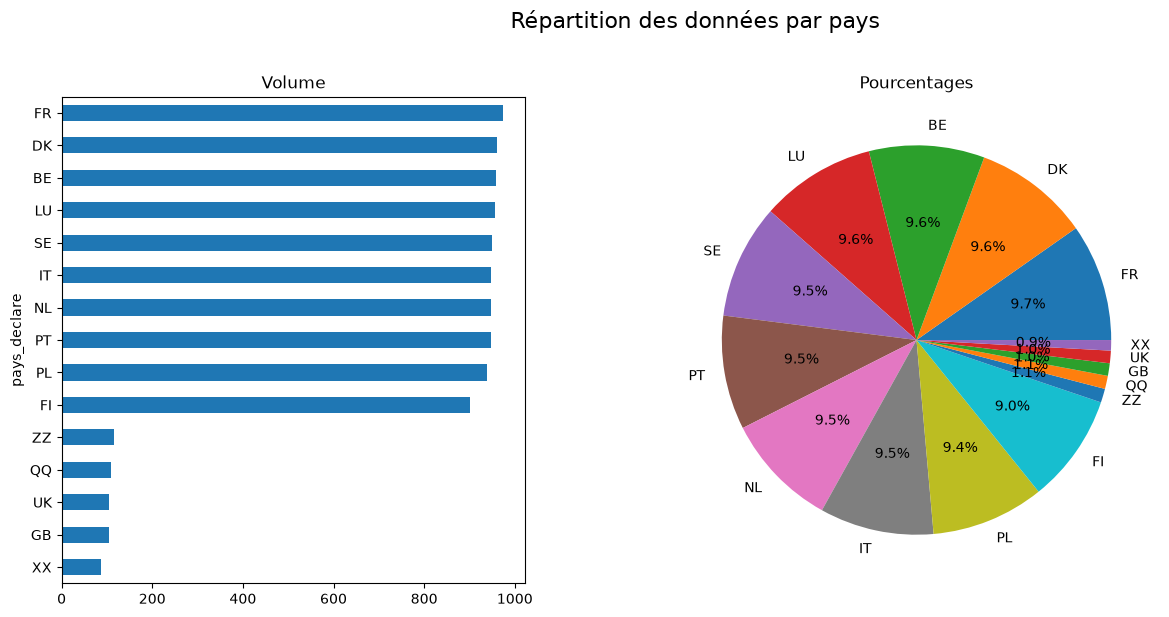

In [740]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6),
                         gridspec_kw={'width_ratios' : [1, 2]})

df_csv['pays_declare'].value_counts(ascending=True).plot(
    kind='barh',
    ax=axes[0],
    title='Volume')
fig.suptitle('Répartition des données par pays', fontsize=16, y=1.02)

df_csv['pays_declare'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    ax=axes[1],
    title='Pourcentages'
)

plt.tight_layout()
plt.show()

####
<div style="
    background: #eebbefff;
    border-left: 5px solid #d619efff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h3 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 400;
    ">
    Version Seaborn
    </h3>
</div>

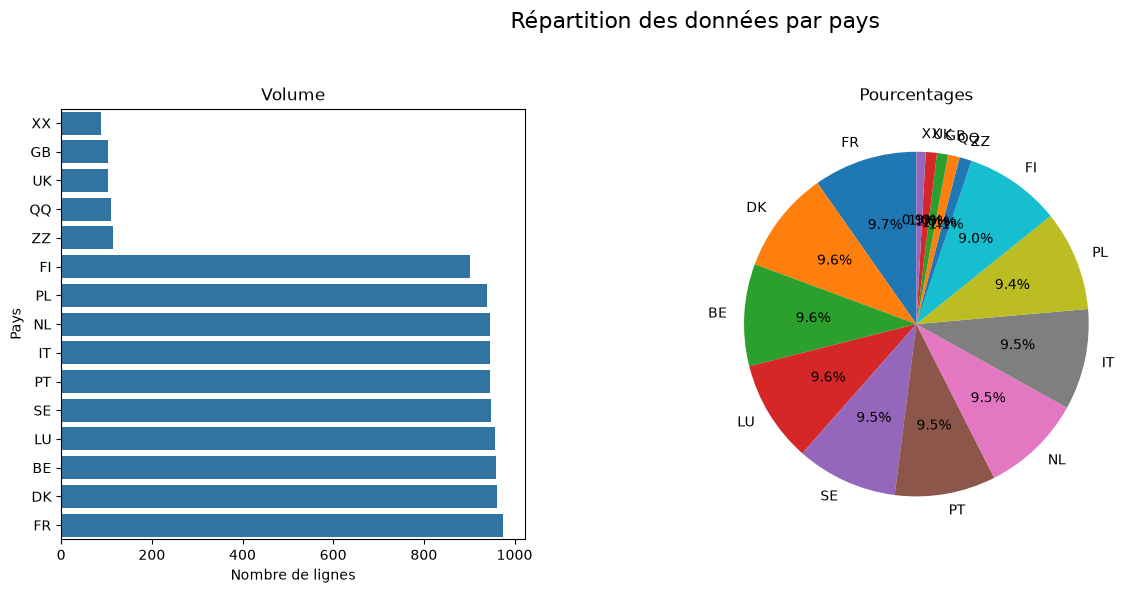

In [741]:
import matplotlib.pyplot as plt
import seaborn as sns

# Comptage des pays
comptages = df_csv['pays_declare'].value_counts()

# Création des deux sous-graphiques
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6),
    gridspec_kw={'width_ratios': [1, 2]}
)

# 1. Graphique horizontal avec Seaborn
sns.countplot(
    data=df_csv,
    y='pays_declare',
    order=comptages.sort_values(ascending=True).index,
    ax=axes[0]
)

axes[0].set_title('Volume')
axes[0].set_xlabel('Nombre de lignes')
axes[0].set_ylabel('Pays')

# 2. Diagramme circulaire avec Matplotlib
axes[1].pie(
    comptages.values,
    labels=comptages.index,
    autopct='%1.1f%%',
    startangle=90
)

axes[1].set_title('Pourcentages')

# Titre global
fig.suptitle('Répartition des données par pays', fontsize=16)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

####
<div style="
    background: #eebbefff;
    border-left: 5px solid #d619efff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h3 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 400;
    ">
    Etude de quelques formats DR
    </h3>
</div>

In [742]:
df_fr = df_csv[df_csv['pays_declare'] == 'FR']
df_fr_notna = df_fr[df_fr['numero_tva'].notna()]
df_fr.sample(20)

,raison_sociale,pays_declare,numero_tva,date_saisie,source_saisie
id,,,,,
6610,Azur Distribution Sp. z o.o.,FR,FR-21378543473,2024-02-23,import_fournisseur
7328,Metallo Consulting NV,FR,FR72263054029,2025-04-09,import_fournisseur
1321,Meridian Logistics BV,FR,FR21399281006,2024-01-28,portail_client
3982,Azur Logistics A/S,FR,FR578517818471,2025-05-20,portail_client
5340,Vertex Technologies Oy,FR,FR39696529558,2024-07-23,crm
8907,Vertex Consulting GmbH,FR,FR41992944228,2025-07-02,reprise_erp
6702,Nord Logistics BV,FR,FR78219066471,2025-02-08,saisie_manuelle
7936,Azur Transports SpA,FR,FR02338083501,2024-07-31,saisie_manuelle
4209,Metallo Trading SpA,FR,FR-38553103256,2024-02-21,saisie_manuelle


In [743]:
import pandas as pd

def identifier_format(tva):

    if pd.isna(tva):
        return 'Manquant (Nan)'

    tva = str(tva).strip().upper()

    if tva.startswith('FR.'):
        return 'FR point ...'

    elif tva.startswith('FR-'):
        return 'FR tiret ...'

    elif tva.startswith('FRH'):
        return 'FRH ...'

    elif tva == 'NULL':
        return 'NULL'

    elif tva == 'N/A':
        return 'N/A'

    elif tva.startswith('FR') and tva[2:].isdigit():
        return f'FR {len(tva[2:])} chiffres'

    elif tva.startswith('FR') and any(c.isalpha() for c in tva):
        return 'FR avec chiffres, lettres'

    elif tva.isdigit():
        return f'{len(tva)} chiffres (Sans FR)'

    elif tva == '-':
        return 'Tiret seul'

    elif tva == '':
        return 'Vide'

    elif ' ' in tva:
        tva = tva.replace(' ', '')

        if tva.startswith('FR') and tva[2:].isdigit():
            return f'FR {len(tva[2:])} chiffres avec des espaces'

        elif any(c.isalpha() for c in tva):
            return 'FR avec chiffres, lettres et espaces'

    return 'Autre format'


# Détection des différents formats
df_fr_format = df_fr.copy()
df_fr_format['format_TVA'] = df_fr_format['numero_tva'].apply(identifier_format)

print(f"Nb de formats : {df_fr_format['format_TVA'].value_counts().shape[0]}")
print(f"Nb de numéros ayant l'un de ces formats : {df_fr_format['format_TVA'].value_counts().sum()} / {df_fr_format.shape[0]}")
print(f"Nb de numéros manquants : {df_fr_format[df_fr_format['format_TVA'] == 'Manquant (Nan)'].shape[0]}")
print(f'Nb de numéros "Autre format" : {df_fr_format[df_fr_format["format_TVA"] == 'Autre format'].shape[0]}')
print("\nListe des différents format :")
list(df_fr_format['format_TVA'].unique())

Nb de formats : 12
Nb de numéros ayant l'un de ces formats : 974 / 974
Nb de numéros manquants : 0
Nb de numéros "Autre format" : 0

Liste des différents format :


['FR 11 chiffres',
 'FR point ...',
 'Vide',
 '11 chiffres (Sans FR)',
 'FR 12 chiffres',
 'FRH ...',
 'FR tiret ...',
 'FR avec chiffres, lettres',
 'FR 10 chiffres',
 'N/A',
 'Tiret seul',
 'NULL']

In [744]:
df_autre_format = df_fr_format[df_fr_format.format_TVA == 'NULL']
df_autre_format

,raison_sociale,pays_declare,numero_tva,date_saisie,source_saisie,format_TVA
id,,,,,,
6228,Cobalt Services Sp. z o.o.,FR,null,2024-05-20,crm,NULL
6575,Cobalt Consulting BV,FR,null,2025-06-10,import_fournisseur,NULL
6745,Nord Industries Lda,FR,null,2024-04-10,import_fournisseur,NULL
8226,Vertex Technologies GmbH,FR,null,2025-09-30,portail_client,NULL
8536,Textil Materials Oy,FR,null,2025-01-22,reprise_erp,NULL
8610,Granit Foods SARL,FR,null,2025-08-28,saisie_manuelle,NULL
9525,Kappa Foods SA,FR,null,2025-09-18,crm,NULL


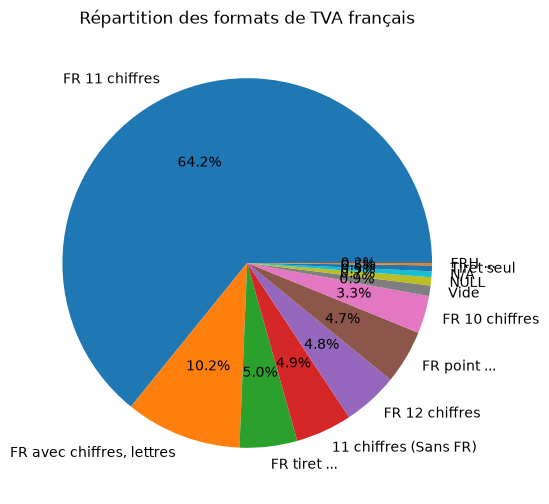

In [745]:
df_fr_format['format_TVA'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(6, 6),
    title='Répartition des formats de TVA français'
)

plt.ylabel('')
plt.show()

##
<div style="
    background: #40f0aa;
    border-left: 5px solid #0c7230ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h2 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Proportion de lignes contenant des caractères qui n'ont rien à faire dans un numéro de TVA ?
    </h2>
</div>

In [746]:
df_spe = df_csv[df_csv['numero_tva'].str.contains(r'[^a-zA-Z0-9]', na=False)]
print(f'Nb de lignes contenant autre chose que des lettres et des chiffres : {df_spe.shape[0]}')
print(f"Proportion de lignes : {100 * df_spe.shape[0] / df_csv.shape[0]:.2f} %")
df_spe.sample(10)
df_spe

Nb de lignes contenant autre chose que des lettres et des chiffres : 1861
Proportion de lignes : 18.61 %


,raison_sociale,pays_declare,numero_tva,date_saisie,source_saisie
id,,,,,
4,Lumen Distribution Sp. z o.o.,SE,SE.751298146001,2024-02-27,import_fournisseur
7,Textil Services Oy,NL,NL505862176B88,2024-10-14,saisie_manuelle
8,Vertex Industries SARL,SE,SE.314125231601,2025-03-31,reprise_erp
11,Hanse Distribution SAS,FI,FI.84564443,2024-01-01,saisie_manuelle
13,Alpine Technologies SAS,SE,SE-353056663101,2024-01-04,portail_client
...,...,...,...,...,...
9986,Prima Logistics BV,SE,SE-744347222501,2024-08-30,reprise_erp
9991,Verso Transports SA,SE,SE 6041 26160001,2025-03-12,saisie_manuelle
9992,Fabrica Materials SpA,LU,LU 8783 8948,2024-12-31,crm


##
<div style="
    background: #40f0aa;
    border-left: 5px solid #0c7230ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h2 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Nombre de valeurs vides
    </h2>
</div>

In [747]:
display(df_csv.isna().sum())
print(f'Nb de valeurs vides parmi les numéros de TVA : {df_csv.isna().sum()['numero_tva']}')

raison_sociale    0
pays_declare      0
numero_tva        0
date_saisie       0
source_saisie     0
dtype: int64

Nb de valeurs vides parmi les numéros de TVA : 0


###
<div style="
    background: #9feaf2ff;
    border-left: 5px solid #1d28c1ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h3 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Recherche des faux NaN
    </h3>
</div>

In [748]:
df_faux_nan = df_csv[df_csv['numero_tva'].str.strip().str.lower().isin(['null', 'n/a', 'nan', '', '-', 'nu.ll'])]
print(f'Nb de faux nan : {df_faux_nan.shape[0]}')
df_faux_nan.sample(10)

Nb de faux nan : 261


,raison_sociale,pays_declare,numero_tva,date_saisie,source_saisie
id,,,,,
9258,Verso Technologies BV,BE,,2025-06-13,reprise_erp
4238,Solaris Services NV,FI,,2025-03-26,portail_client
5635,Meridian Trading Oy,NL,-,2024-12-26,import_fournisseur
3390,Atlantic Distribution Sp. z o.o.,BE,,2024-02-25,saisie_manuelle
2396,Corvus Trading GmbH,FI,null,2025-08-06,import_fournisseur
2639,Solaris Transports SA,FI,N/A,2024-11-15,crm
2175,Kappa Services NV,PT,,2024-04-27,saisie_manuelle
7153,Vertex Trading BV,SE,,2025-09-29,portail_client
8969,Papyrus Technologies BV,BE,,2024-11-19,reprise_erp


On a 6 différents types de faux Nan :
- 'null'
- 'n/a'
- 'nan'
- ''
- '-'
- 'nu.ll (ou NU.LL)

##
<div style="
    background: #40f0aa;
    border-left: 5px solid #0c7230ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h2 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Le pays déclaré dans le CRM correspond-il toujours au préfixe du numéro ?
    </h2>
</div>

In [749]:
df_code_country = df_csv.copy()
df_code_country['code_pays_OK'] = df_code_country.apply(
    lambda x : x['pays_declare'].lower() in str(x['numero_tva']).lower(),
    axis = 1
)

print(f"Codes pays correspondants au numéro de TVA : {df_code_country['code_pays_OK'].sum()} / {df_csv.shape[0]}")
print(f"Proportion de codes pays correspondants au numéro de TVA : {100 * df_code_country['code_pays_OK'].sum() / df_csv.shape[0]:.2f} %")

df_code_country[~df_code_country.code_pays_OK].sample(10)

Codes pays correspondants au numéro de TVA : 9207 / 10000
Proportion de codes pays correspondants au numéro de TVA : 92.07 %


,raison_sociale,pays_declare,numero_tva,date_saisie,source_saisie,code_pays_OK
id,,,,,,
6893,Vela Transports BV,PL,9394459296,2025-09-20,crm,False
7434,Verso Foods GmbH,FR,,2024-04-12,crm,False
687,Lumen Consulting BV,NL,,2024-07-14,reprise_erp,False
5324,Lusitania Transports GmbH,NL,913629686B19,2024-10-19,crm,False
1222,Corvus Distribution SpA,IT,-,2025-03-29,import_fournisseur,False
8248,Verso Services GmbH,BE,1357128582,2024-11-13,import_fournisseur,False
5080,Fabrica Transports A/S,PL,-,2025-05-09,import_fournisseur,False
6974,Lumen Trading AB,FR,21255993964,2024-06-22,import_fournisseur,False
7699,Delta Transports Lda,PT,479254400,2025-08-21,crm,False


##
<div style="
    background: #40f0aa;
    border-left: 5px solid #0c7230ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h2 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Comparaison des fichiers CVS et Excel
    </h2>
</div>

**Le CSV et l'Excel contiennent-ils vraiment la même chose une fois chargés ? Lequel prenez-vous comme source de vérité, et pourquoi ?**

In [750]:
# Les noms de colonnes des 2 fichiers sont identiques
print(f'Colonnes du fichier CSV :\t {list(df_csv.columns)}')
print(f'Colonnes du fichier XL  :\t {list(df_xl.columns)}')

Colonnes du fichier CSV :	 ['raison_sociale', 'pays_declare', 'numero_tva', 'date_saisie', 'source_saisie']
Colonnes du fichier XL  :	 ['raison_sociale', 'pays_declare', 'numero_tva', 'date_saisie', 'source_saisie']


In [751]:
# Il y a le même nombre de lignes et de colonnes dans les 2 fichiers
print(f'Taille des données dans le fichier CSV :\t{df_csv.shape}')
print(f'Taille des données dans le fichier XL  :\t{df_csv.shape}')

Taille des données dans le fichier CSV :	(10000, 5)
Taille des données dans le fichier XL  :	(10000, 5)


In [752]:
# Les différences de données entre les 2 fichiers sont dans la colonne : "numero_tva"
print(f"Il y a {df_csv['numero_tva'].shape[0] - (df_csv['numero_tva'] == df_xl['numero_tva']).sum()} valeurs différentes entre les 2 fichiers")
(df_csv == df_xl).sum()

Il y a 0 valeurs différentes entre les 2 fichiers


raison_sociale    10000
pays_declare      10000
numero_tva        10000
date_saisie       10000
source_saisie     10000
dtype: int64

**Conclusion :** 

Les 2 fichiers sont identiques, on utilisera de préférence le fichier CSV car en entreprise les utilisateurs modifient rarement un fichiers CSV alors qu'ils pourraient facilement modifier un fichier Excel.

**Remarque** :

Lors de la lecture des fichiers, on impose de transformer les données en "str" y compris les valeurs vides (NaN), sans ça nos dataframe contiendraient des NaN et il y aurait alors des différences entre les 2 fichiers.

##
<div style="
    background: #40f0aa;
    border-left: 5px solid #0c7230ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h2 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Canaux de saisie et périodes de saisie
    </h2>
</div>

**Les canaux de saisie et les périodes de saisie se ressemblent-ils, ou certains sortent-ils du lot ?**

###
<div style="
    background: #9feaf2ff;
    border-left: 5px solid #1d28c1ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h3 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Canaux de saisie
    </h3>
</div>

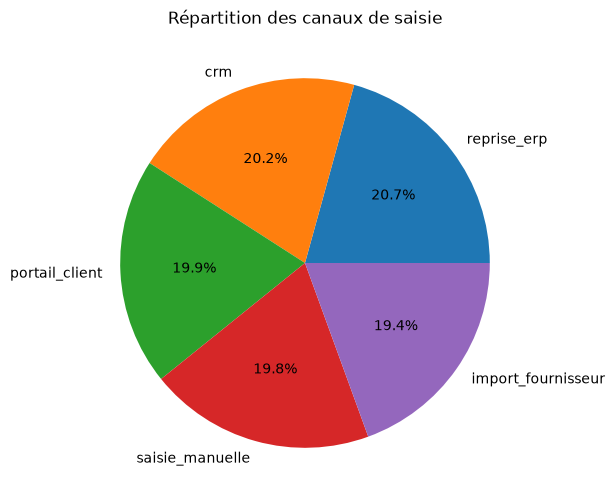

In [753]:
df_csv['source_saisie'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(6, 6),
    title='Répartition des canaux de saisie'
)

plt.ylabel('')
plt.show()

**Tous les canaux de saisie sont bien renseignés et appartiennent à 5 catégories** :<br>
- crm
- reprise_erp
- portail_client
- saisie_manuelle
- import_fournisseur

###
<div style="
    background: #9feaf2ff;
    border-left: 5px solid #1d28c1ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h3 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Dates de saisie
    </h3>
</div>

**Le type des dates est "String", nous allons le convertir en date**

In [754]:
display(df_csv['date_saisie'].dtypes)
df_csv['date_saisie'] = pd.to_datetime(df_csv['date_saisie'], format="%Y-%m-%d", errors='coerce')
display(df_csv.dtypes)

<StringDtype(storage='python', na_value=nan)>

raison_sociale               str
pays_declare                 str
numero_tva                   str
date_saisie       datetime64[us]
source_saisie                str
dtype: object

**On ajoute des colonnes avec l'année et avec "année-mois"**

In [755]:
df_csv['annee'] = df_csv['date_saisie'].dt.year
df_csv['date_mois'] = df_csv['date_saisie'].dt.to_period('M')
df_csv.sample(5)

,raison_sociale,pays_declare,numero_tva,date_saisie,source_saisie,annee,date_mois
id,,,,,,,
1115,Textil Industries NV,PT,N/A,2025-05-10,crm,2025,2025-05
6152,Ardent Consulting AB,FR,FR3943750492,2024-08-18,crm,2024,2024-08
2282,Prima Logistics AB,LU,LU79404879,2024-10-08,saisie_manuelle,2024,2024-10
9597,Solaris Logistics Sp. z o.o.,FI,FI59519069,2024-01-09,crm,2024,2024-01
2741,Papyrus Industries AB,SE,SE665644448101,2025-04-26,portail_client,2025,2025-04


**On peut afficher la répartition des dates par année**

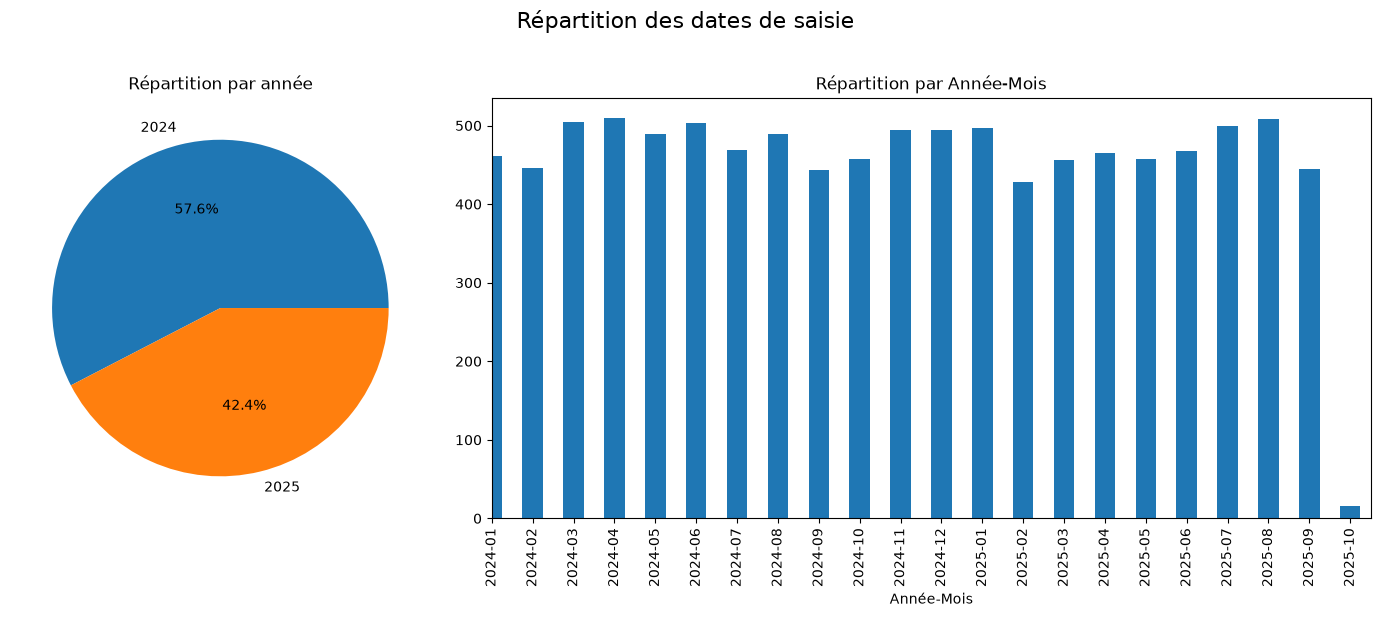

In [756]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6),
                         gridspec_kw={'width_ratios' : [1, 2]})

df_csv['annee'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    ax=axes[0],
    title='Répartition par année'
)

df_csv['date_mois'].value_counts().plot(
    kind='bar', 
    xlabel='Année-Mois',
    title='Répartition par Année-Mois',
    ax=axes[1]
    )

# Ajustement de la disposition
plt.suptitle("Répartition des dates de saisie", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

####
<div style="
    background: #eebbefff;
    border-left: 5px solid #d619efff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h3 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 400;
    ">
    Version Seaborn
    </h3>
</div>

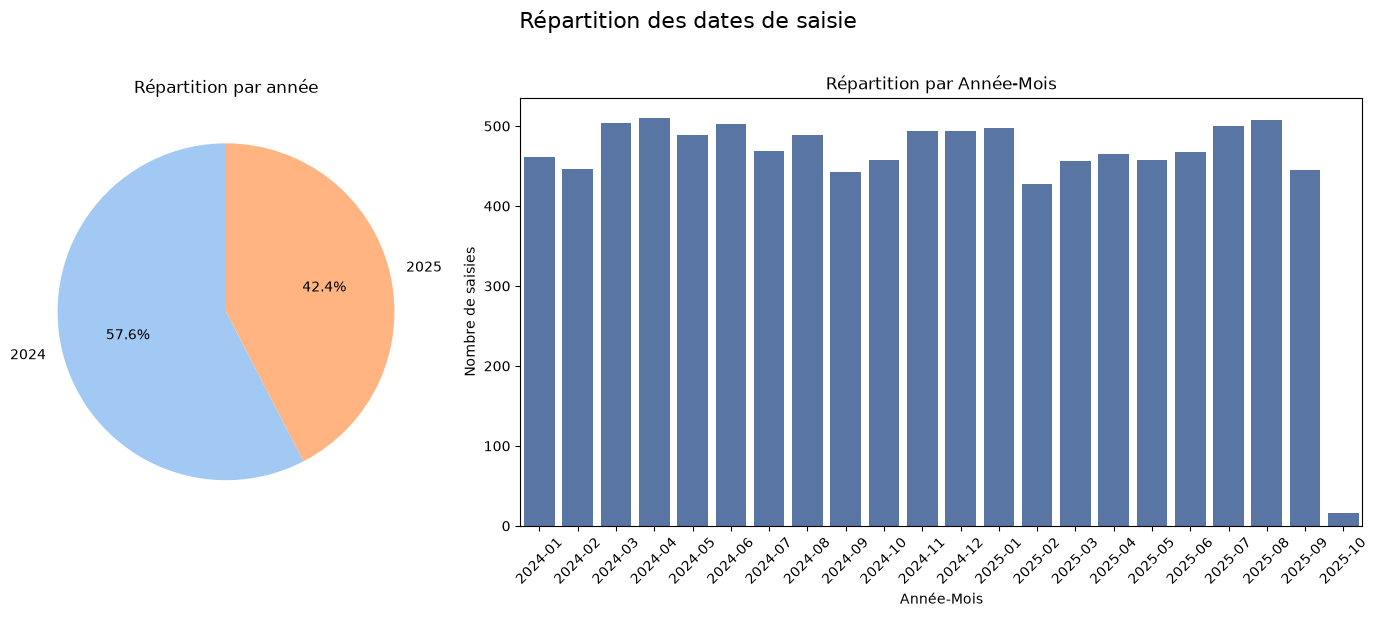

In [757]:
import matplotlib.pyplot as plt
import seaborn as sns

# Préparation des données
annees = df_csv['annee'].value_counts().sort_index()

# Conversion en texte pour faciliter l'affichage des mois
df_plot = df_csv.copy()
df_plot['date_mois'] = df_plot['date_mois'].astype(str)

ordre_mois = sorted(df_plot['date_mois'].dropna().unique())

# Création des sous-graphiques
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6),
    gridspec_kw={'width_ratios': [1, 2]}
)

# 1. Diagramme circulaire avec Matplotlib
axes[0].pie(
    annees.values,
    labels=annees.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=sns.color_palette('pastel', len(annees))
)

axes[0].set_title('Répartition par année')

# 2. Diagramme en barres avec Seaborn
sns.countplot(
    data=df_plot,
    x='date_mois',
    order=ordre_mois,
    ax=axes[1],
    color=sns.color_palette('deep')[0]
)

axes[1].set_title('Répartition par Année-Mois')
axes[1].set_xlabel('Année-Mois')
axes[1].set_ylabel('Nombre de saisies')
axes[1].tick_params(axis='x', rotation=45)

# Titre global
fig.suptitle(
    'Répartition des dates de saisie',
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

**On peut aussi faire un graphique de type "Sunburst" pour afficher deux niveaux**

C:\Users\Utilisateur\AppData\Local\Temp\ipykernel_10000\3704038135.py:10: Pandas4Warning: PeriodIndex.values returning an object-dtype ndarray is deprecated. In a future version, this will return the underlying PeriodArray instead. Use 'PeriodIndex.to_numpy()' to get a NumPy array, or 'PeriodIndex.array' to get the ExtensionArray.
  sous_categories = count_annee_mois.index.values


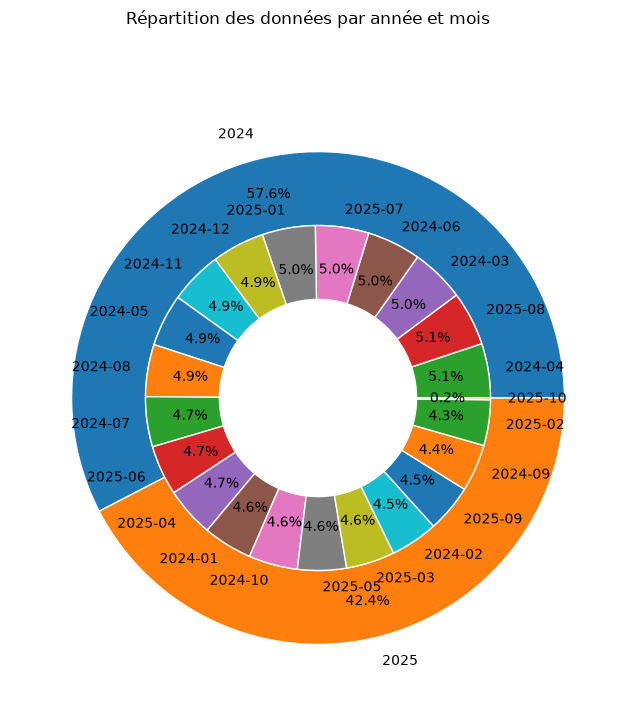

In [758]:
fig, ax = plt.subplots(figsize=(8, 8))

# Niveau 1 : Année
count_annee = df_csv['annee'].value_counts()
categories = count_annee.index.values
valeurs = count_annee.values

# Niveau 2 : Année-Mois
count_annee_mois = df_csv['date_mois'].value_counts()
sous_categories = count_annee_mois.index.values
sous_valeurs = count_annee_mois.values

# Premier niveau
ax.pie(
    valeurs,
    radius=1,
    labels=categories,
    autopct='%1.1f%%',
    pctdistance=0.85,
    wedgeprops=dict(width=0.3, edgecolor='white')
)

# Deuxième niveau
ax.pie(
    sous_valeurs,
    radius=0.7,
    labels=sous_categories,
    autopct='%1.1f%%',
    pctdistance=0.75,
    wedgeprops=dict(width=0.3, edgecolor='white')
)

plt.suptitle("Répartition des données par année et mois")
plt.show()

##
<div style="
    background: #40f0aa;
    border-left: 5px solid #0c7230ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h2 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Supplément : Répartition des sources en fonction du pays
    </h2>
</div>

On filtre des dataframe les pays ayant plus de 200 données.

On regroupe par "pays" puis par "source".

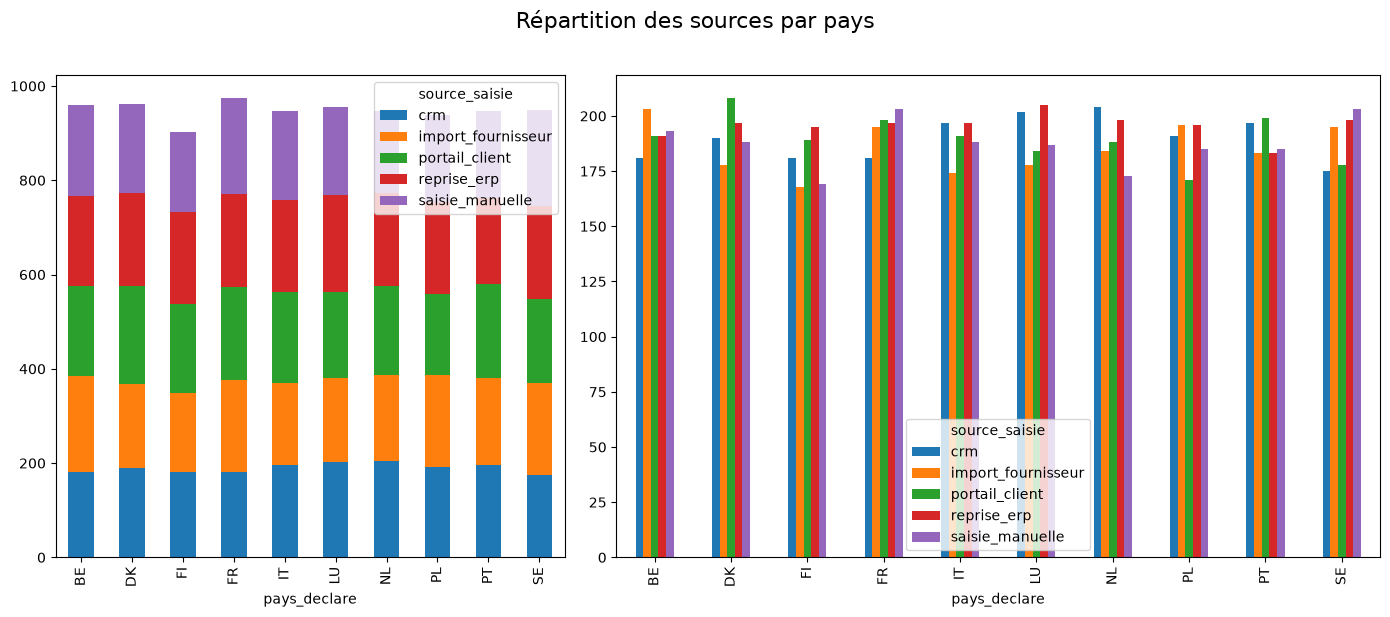

In [759]:
comptage = df_csv['pays_declare'].value_counts()
pays_importants = comptage[comptage > 200].index
df_filtre = df_csv[df_csv['pays_declare'].isin(pays_importants)]

df_group = df_filtre.groupby(
    ['pays_declare', 'source_saisie']
).size()

fig, axes = plt.subplots(1, 2, figsize=(14, 6),
                         gridspec_kw={'width_ratios' : [2, 3]})

df_group.unstack().plot(
    kind='bar',
    stacked=True,
    ax = axes[0],
)

df_group.unstack().plot(
    kind='bar',
    ax = axes[1],
)

# Ajustement de la disposition
plt.suptitle("Répartition des sources par pays", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()